# Paper figures from `experiments/`

Rebuilds the paper's result plots, reading the raw runs straight from
`../experiments/<POLICY>/<run>/summary.jsonl`:

1. LRU vs S3-FIFO simplex over all 21 measured mixes
2. Ablation figure (best policy flips within a fixed mix)

Figures are shown inline and also written to `analysis/figures/`.

Self-contained — requirements: `numpy`, `pandas`, `matplotlib`. Run from the `analysis/` folder.

In [ ]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

%matplotlib inline

EXP = Path("../experiments").resolve()
OUT = Path("figures"); OUT.mkdir(exist_ok=True)
print("experiments:", EXP, "->", sorted(p.name for p in EXP.iterdir() if p.is_dir()))

## Reading results

In [30]:
def read_summary(path):
    """summary.jsonl -> {metric: record}; None if missing/empty."""
    path = Path(path)
    if not path.exists():
        return None
    rec = {}
    for line in path.read_text().splitlines():
        try:
            j = json.loads(line)
        except json.JSONDecodeError:
            continue
        rec[j.get("metric")] = j
    return rec or None


def extract_metric(summary_path, key):
    """Search every JSONL record for `key` (top-level or one level nested)."""
    with open(summary_path) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                rec = json.loads(line)
            except json.JSONDecodeError:
                continue
            if key in rec:
                return float(rec[key])
            for v in rec.values():
                if isinstance(v, dict) and key in v:
                    return float(v[key])
    return None

## 1. Simplex gradient — LRU vs S3-FIFO (all 21 measured mixes)

Every `gold_config_s*_m*_a*` mix that both LRU and S3-FIFO have, gradient-filled by linear interpolation
between the measured mixes. Metric: `real_cum_hit_rate`.

In [31]:
RUN_PREFIX = "gold_config"
METRIC = "real_cum_hit_rate"
CMAP = "YlGnBu"

POLICIES = [("LRU", "LRU"), ("S3FIFO", "S3-FIFO")]
SQRT3_2 = np.sqrt(3) / 2.0


def bary(s, m, a):
    """(single, multi, agent) percentages -> 2D triangle coords.
    ST bottom-left, MT top, AT bottom-right."""
    tot = (s + m + a) or 1.0
    s, m, a = 100.0 * s / tot, 100.0 * m / tot, 100.0 * a / tot
    return a / 100.0 + 0.5 * m / 100.0, SQRT3_2 * m / 100.0


def _frame(ax):
    """Draw triangle outline, 20% gridlines, and corner labels."""
    v = [bary(100, 0, 0), bary(0, 100, 0), bary(0, 0, 100)]
    tx, ty = zip(*(v + [v[0]]))
    ax.plot(tx, ty, "k-", lw=1.1, zorder=2)
    for t in range(20, 100, 20):
        for p, q in (((t, 100 - t, 0), (t, 0, 100 - t)),
                     ((100 - t, t, 0), (0, t, 100 - t)),
                     ((100 - t, 0, t), (0, 100 - t, t))):
            (x0, y0), (x1, y1) = bary(*p), bary(*q)
            ax.plot([x0, x1], [y0, y1], color="0.85", lw=0.5, zorder=1)
    for lab, pt, dy, va in (("Single", (100, 0, 0), -0.05, "top"),
                            ("Multi", (0, 100, 0), 0.05, "bottom"),
                            ("Agent", (0, 0, 100), -0.05, "top")):
        bx, by = bary(*pt)
        ax.text(bx, by + dy, lab, ha="center", va=va, fontweight="bold", fontsize=8)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_xlim(-0.12, 1.12)
    ax.set_ylim(-0.16, SQRT3_2 + 0.14)


def frame_pct(ax):
    """_frame plus percentage ticks on each edge, so every point reads as a traffic mix.
    Bottom edge: % agentic, right edge: % multi-turn, left edge: % single-turn."""
    _frame(ax)
    for txt in ax.texts:  # corner names from _frame -> "100% <type>"
        if txt.get_text() in ("Single", "Multi", "Agent"):
            name = txt.get_text()
            txt.set_text(f"100% {name}")
            if name in ("Single", "Agent"):  # two lines so it stays narrow, clear of the edge ticks
                txt.set_text(f"100%\n{'Agentic chats' if name == 'Agent' else name}")
                txt.set_position((0.0 if name == "Single" else 1.0, -0.04))
                txt.set_ha("center"); txt.set_va("top"); txt.set_linespacing(1.1)
    H = np.sqrt(3) / 2
    edges = [  # (point on edge for value t, outward normal, rotation, axis title, title position)
        (lambda t: (100 - t, 0, t), (0.0, -1.0), 0, "Agentic (%)", (0.5, -0.17)),
        (lambda t: (0, t, 100 - t), (H, 0.5), -60, "Multi-turn (%)", (0.86, 0.5)),
        (lambda t: (t, 100 - t, 0), (-H, 0.5), 60, "Single-turn (%)", (0.14, 0.5)),
    ]
    for pt, (nx, ny), rot, title, (tx, ty) in edges:
        for t in (20, 40, 60, 80):
            x, y = bary(*pt(t))
            ax.plot([x, x + nx * 0.02], [y, y + ny * 0.02], color="k", lw=0.8, zorder=2)
            ax.text(x + nx * 0.06, y + ny * 0.06, f"{t}%", ha="center", va="center",
                    fontsize=6.5, rotation=rot, color="0.25")
        ax.text(tx + nx * 0.08, ty + ny * 0.08, title, ha="center", va="center",
                fontsize=7.5, rotation=rot, color="0.25")
    ax.set_xlim(-0.2, 1.2)
    ax.set_ylim(-0.24, 0.94)


def points(ax, pts, vals, cmap, norm):
    """Smooth gradient fill + colored circles at the measured mixes."""
    xs, ys = zip(*[bary(*p) for p in pts])
    tri = mtri.Triangulation(xs, ys)
    rtri, rvals = mtri.UniformTriRefiner(tri).refine_field(np.asarray(vals), subdiv=4)
    ax.tripcolor(rtri, rvals, cmap=cmap, norm=norm, shading="gouraud", zorder=0, rasterized=True)
    return ax.scatter(xs, ys, c=vals, cmap=cmap, norm=norm, s=110,
                      edgecolors="k", linewidths=0.5, zorder=3)

In [32]:
def load_simplex(root, algo_dir, prefix=RUN_PREFIX, metric=METRIC):
    """-> {(s,m,a): value} for every gold_config mix on disk for one policy."""
    out = {}
    name_re = re.compile(rf"^{re.escape(prefix)}_s(\d+)_m(\d+)_a(\d+)$")
    for d in sorted((Path(root) / algo_dir).iterdir()):
        m = name_re.match(d.name)
        p = d / "summary.jsonl"
        if m and p.is_file() and p.stat().st_size:
            v = extract_metric(p, metric)
            if v is not None:
                out[tuple(int(x) for x in m.groups())] = v
    return out


data = {d: load_simplex(EXP, d) for d, _ in POLICIES}
keep = set(data["LRU"]) & set(data["S3FIFO"])
data = {d: {c: v for c, v in vals.items() if c in keep} for d, vals in data.items()}
diff = {c: data["S3FIFO"][c] - data["LRU"][c] for c in sorted(keep)}
print(f"{len(keep)} mixes shared by LRU and S3-FIFO")
pd.DataFrame({"LRU": data["LRU"], "S3FIFO": data["S3FIFO"], "S3FIFO-LRU": diff}).sort_index().round(4)

21 mixes shared by LRU and S3-FIFO


LRU  S3FIFO  S3FIFO-LRU
0   0   100  0.6927  0.5756     -0.1171
    30  70   0.5910  0.5100     -0.0810
    50  50   0.4949  0.4682     -0.0267
    70  30   0.3427  0.4088      0.0660
    100 0    0.0842  0.2603      0.1761
10  20  70   0.6037  0.5214     -0.0823
    70  20   0.2744  0.3994      0.1250
20  10  70   0.6243  0.5343     -0.0900
    70  10   0.2261  0.3830      0.1569
30  0   70   0.6442  0.5609     -0.0833
    30  40   0.5092  0.5040     -0.0052
    40  30   0.4279  0.4733      0.0454
    70  0    0.1419  0.3656      0.2237
40  30  30   0.4534  0.5082      0.0548
50  0   50   0.6126  0.5946     -0.0180
    50  0    0.2336  0.4140      0.1804
70  0   30   0.5534  0.6001      0.0467
    10  20   0.4984  0.5563      0.0580
    20  10   0.4351  0.5170      0.0819
    30  0    0.3151  0.4536      0.1385
100 0   0    0.3783  0.4945      0.1162

### 1a. S3-FIFO − LRU  →  `figures/simplex_all_s3fifo_minus_lru.{png,pdf}`

Purple = S3-FIFO higher hit rate, orange = LRU higher.

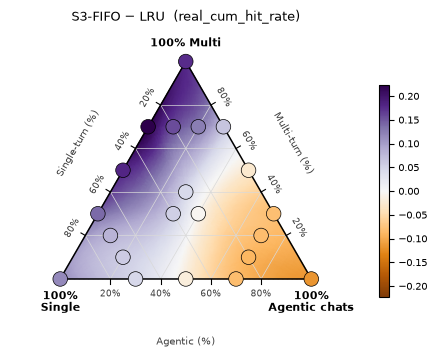

In [33]:
lim = max(abs(v) for v in diff.values()) or 1e-6
dnorm = plt.Normalize(-lim, lim)

fig, ax = plt.subplots(figsize=(5.6, 4.6))
frame_pct(ax)
pts = list(diff)
sc = points(ax, pts, [diff[p] for p in pts], "PuOr", dnorm)
fig.colorbar(sc, ax=ax, shrink=0.6, aspect=22, pad=0.04).ax.tick_params(labelsize=7)
ax.set_title(f"S3-FIFO − LRU  ({METRIC})", fontsize=9, pad=16)
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"simplex_all_s3fifo_minus_lru.{ext}", dpi=150, bbox_inches="tight")
plt.show()

### 1b. LRU | S3-FIFO | S3-FIFO − LRU  →  `figures/simplex_all_lru_s3fifo.{png,pdf}`

The two hit-rate triangles share one color scale.

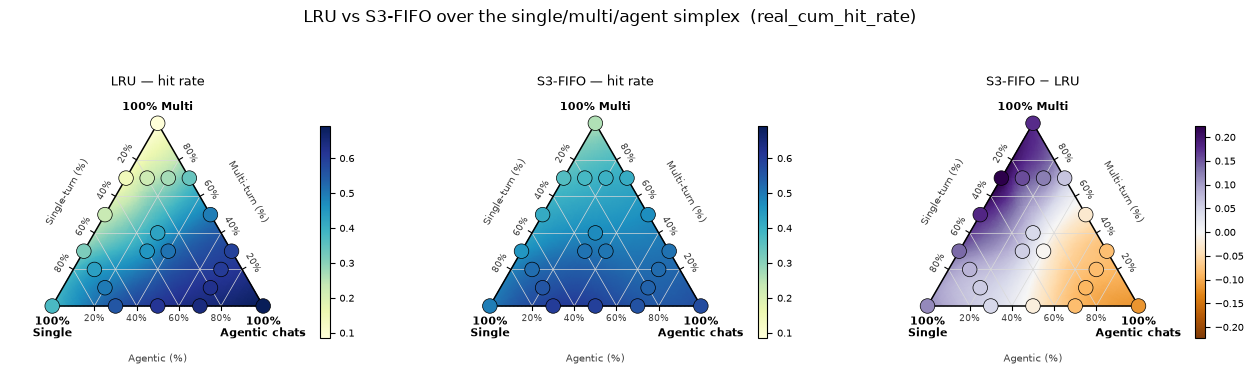

In [34]:
allv = [v for d in data.values() for v in d.values()]
norm = plt.Normalize(min(allv), max(allv))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (d, label) in zip(axes[:2], POLICIES):
    frame_pct(ax)
    pts = list(data[d])
    sc = points(ax, pts, [data[d][p] for p in pts], CMAP, norm)
    fig.colorbar(sc, ax=ax, shrink=0.6, aspect=22, pad=0.04).ax.tick_params(labelsize=7)
    ax.set_title(f"{label} — hit rate", fontsize=9, pad=16)

ax = axes[2]
frame_pct(ax)
pts = list(diff)
sc = points(ax, pts, [diff[p] for p in pts], "PuOr", dnorm)
fig.colorbar(sc, ax=ax, shrink=0.6, aspect=22, pad=0.04).ax.tick_params(labelsize=7)
ax.set_title("S3-FIFO − LRU", fontsize=9, pad=16)

fig.suptitle(f"LRU vs S3-FIFO over the single/multi/agent simplex  ({METRIC})", fontsize=12)
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"simplex_all_lru_s3fifo.{ext}", dpi=150, bbox_inches="tight")
plt.show()

## 2. Ablation figure — the best eviction policy flips within a fixed request mix

Reads `experiments/<POLICY>/ablations_<sweep>_s<S>_m<M>_a<A>_<type>_<key><value>/summary.jsonl`.
Hit rate = `cached_tokens / prompt_tokens` from the `Prefix Cache` record. No filtering — each panel
picks exactly the runs it plots.

In [35]:
ABL = re.compile(r"ablations_(input_lengths|output_lengths|num_services|turns|inter_turn_time)"
                 r"_s(\d+)_m(\d+)_a(\d+)_(single|multi_turn|agentic)_(?:in|out|svc|turns|itt)(\d+)$")

POL = ["LRU", "S3FIFO", "DYNAMIC"]
LABEL = {"LRU": "LRU", "S3FIFO": "S3FIFO", "DYNAMIC": "Dynamic"}
COLOR = {"LRU": "#2a78d6", "S3FIFO": "#1baf7a", "DYNAMIC": "#eb6834"}
MARK = {"LRU": "o", "S3FIFO": "D", "DYNAMIC": "^"}
INK, INK2, MUTED, GRID = "#1f1f1e", "#52514e", "#8a8984", "#e6e5e0"

ABL_RC = {
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "axes.edgecolor": MUTED,
    "axes.linewidth": 0.6, "xtick.color": INK2, "ytick.color": INK2,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "pdf.fonttype": 42,
}


def load_ablations(exp_dir):
    rows = []
    for pol in POL:
        for run in sorted((exp_dir / pol).glob("ablations_*")):
            m = ABL.match(run.name)
            sm = read_summary(run / "summary.jsonl")
            if not m or not sm or "Prefix Cache" not in sm:
                continue  # unfinished run
            pc = sm["Prefix Cache"]
            rows.append(dict(policy=pol, sweep=m[1], mix=f"{m[2]}/{m[3]}/{m[4]}", swept_type=m[5],
                             value=int(m[6]), hit_rate=100 * pc["cached_tokens"] / pc["prompt_tokens"]))
    if not rows:
        raise SystemExit(f"No finished ablation runs found under {exp_dir}")
    P = pd.DataFrame(rows).pivot_table(index=["sweep", "mix", "swept_type", "value"],
                                       columns="policy", values="hit_rate")
    return P.reindex(columns=POL).dropna()


P = load_ablations(EXP)
P.round(2)

policy                                      LRU  S3FIFO  DYNAMIC
sweep         mix      swept_type value                         
input_lengths 0/50/50  agentic    128     50.46   49.25    49.95
                                  1024    47.68   44.87    47.49
                                  8192     2.53    2.55     2.68
                                  32768    0.73    0.93     0.75
                                  131072   1.48    1.43     1.58
...                                         ...     ...      ...
turns         33/33/33 multi_turn 4       46.02   50.92    45.56
                                  8       33.47   48.85    41.14
              50/50/0  multi_turn 2       23.92   32.41    30.46
                                  4       17.56   50.10    46.40
                                  8       18.12   58.70    56.19

[94 rows x 3 columns]

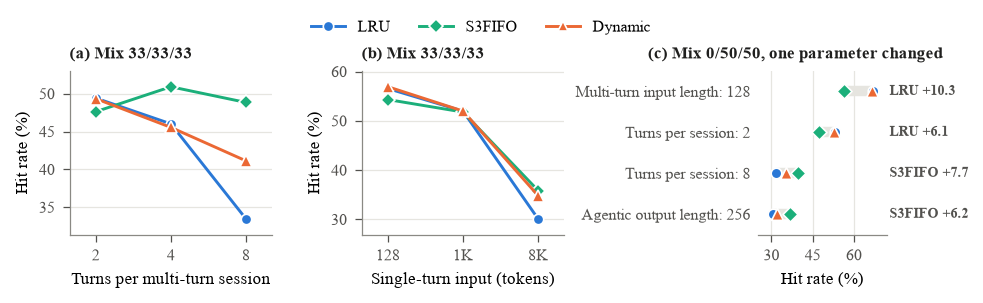

In [36]:
def style(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)


def sweep_panel(ax, P, sweep, typ, values, xlabels, title, xlabel):
    S = P.loc[[(sweep, "33/33/33", typ, v) for v in values]]
    x = range(len(S))
    for p in POL:
        ax.plot(x, S[p], color=COLOR[p], lw=1.4, marker=MARK[p], ms=5 if p != "DYNAMIC" else 5.5,
                mec="white", mew=0.8, zorder=3 if p == "DYNAMIC" else 2)
    lo, hi = S[POL].min().min(), S[POL].max().max()
    pad = (hi - lo) * 0.12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xticks(list(x), xlabels)
    ax.set_xlim(-0.35, len(S) - 0.65)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Hit rate (%)")
    ax.set_title(title, fontsize=8, color=INK, loc="left", fontweight="bold")
    style(ax)


def same_mix_panel(ax, P):
    rows = [  # (label, key) — one parameter changed per row, mix fixed at 0/50/50
        ("Multi-turn input length: 128", ("input_lengths", "0/50/50", "multi_turn", 128)),
        ("Turns per session: 2", ("turns", "0/50/50", "multi_turn", 2)),
        ("Turns per session: 8", ("turns", "0/50/50", "multi_turn", 8)),
        ("Agentic output length: 256", ("output_lengths", "0/50/50", "agentic", 256)),
    ]
    for i, (_, k) in enumerate(rows):
        r = P.loc[k]
        lo, hi = min(r.LRU, r.S3FIFO), max(r.LRU, r.S3FIFO)
        ax.plot([lo, hi], [i, i], color=GRID, lw=5, solid_capstyle="round", zorder=1)
        for p in POL:
            ax.scatter(r[p], i, marker=MARK[p], s=26 if p != "DYNAMIC" else 32, color=COLOR[p],
                       edgecolors="white", linewidths=0.8, zorder=3 if p == "DYNAMIC" else 2)
        gap = r.S3FIFO - r.LRU
        w = "S3FIFO" if gap > 0 else "LRU"
        ax.text(1.02, i, f"{w} +{abs(gap):.1f}", transform=ax.get_yaxis_transform(),
                va="center", fontsize=6.5, color=INK2, fontweight="bold")
    ax.set_yticks(range(len(rows)), [r[0] for r in rows])
    ax.set_ylim(len(rows) - 0.5, -0.5)
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="x", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.set_xlim(25, 72)
    ax.set_xticks([30, 45, 60])
    ax.set_xlabel("Hit rate (%)")
    ax.set_title("(c) Mix 0/50/50, one parameter changed", fontsize=8, color=INK, loc="left",
                 fontweight="bold", x=-0.85)


with plt.rc_context(ABL_RC):
    fig = plt.figure(figsize=(6.3, 1.95), dpi=150)
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.15], wspace=0.42, left=0.065, right=0.93,
                          bottom=0.22, top=0.78)
    sweep_panel(fig.add_subplot(gs[0]), P, "turns", "multi_turn", [2, 4, 8], ["2", "4", "8"],
                "(a) Mix 33/33/33", "Turns per multi-turn session")
    sweep_panel(fig.add_subplot(gs[1]), P, "input_lengths", "single", [128, 1024, 8192], ["128", "1K", "8K"],
                "(b) Mix 33/33/33", "Single-turn input (tokens)")
    cax = fig.add_subplot(gs[2])
    same_mix_panel(cax, P)
    pos = cax.get_position()
    cax.set_position([pos.x0 + 0.11, pos.y0, pos.width - 0.11, pos.height])
    handles = [plt.Line2D([0], [0], color=COLOR[p], marker=MARK[p], lw=1.4, ms=5, mec="white",
                          mew=0.8, label=LABEL[p]) for p in POL]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=3,
               frameon=False, fontsize=7.5, handlelength=2.2, columnspacing=1.8)
    fig.savefig(OUT / "ablation_same_mix.pdf", bbox_inches="tight", pad_inches=0.02)
    fig.savefig(OUT / "ablation_same_mix.png", dpi=200, bbox_inches="tight", pad_inches=0.02)
    plt.show()